# Ingresos: cuantiles, bandas y cobertura por segmento

## Resumen de la ejecución

Datos sintéticos; resultados de esta ejecución:

- **Cobertura nominal:** 0.8
- **Cobertura test ampliada:** 0.7829
- **Cobertura con cambio de ingreso:** 0.2057
- **Ampliación en log puntos:** 0.0097
- **Cobertura modelo de dos partes:** 0.896
- **AP de sobrerreporte sintético:** 0.7895
- **Error máximo de pinball en grilla:** 0.0013

Los supuestos, límites y contraejemplos se explican junto a cada experimento.

## Objetivo y método

¿Qué rango de ingreso es compatible con una actividad y cuánta incertidumbre conserva? Ajustamos cuantiles, ampliamos bandas con una calibración separada y distinguimos cobertura de detección de fraude.

### Supuestos y población

Ingreso mensual corroborado simulado, en COP. Mezcla de asalariados e independientes con ruido diferente. Entrenamiento, calibración y test son independientes y estacionarios por construcción; no se presupone intercambiabilidad de una cartera real.

Todos los datos son sintéticos. Las cifras ilustran mecanismos y no constituyen desempeño observado en una entidad. Fecha de desarrollo: 21 de octubre de 2026.

## Entorno reproducible

Ejecutar en orden, desde esta carpeta o una subcarpeta de la línea de fraude. La semilla y los parámetros quedan en las celdas; no se consulta internet ni se leen datos de clientes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score, brier_score_loss
base = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == 'fraud-and-anomaly-research')
sys.path.insert(0, str(base / 'loss-minimization-engine'))
from src.engine import Case, Action, Scenario, optimize, expected_cost, shared_entity_count
rng = np.random.default_rng(20261021)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': .25})
BLUE, TEAL, GOLD, PURPLE = '#386A96', '#217A72', '#B37D2E', '#73579D'
pd.options.display.float_format = '{:,.4f}'.format

No event loop hook running.


## 1. Pérdida cuantílica y mecanismo generador


$$\rho_\tau(u)=u(\tau-\mathbf{1}_{u<0}),\quad \hat q_\tau(x)=\arg\min_f\sum_i\rho_\tau(y_i-f(x_i)).$$

Modelamos $y=\log(I)$ con $I>0$ y cuantiles 0,1 y 0,9 para una banda nominal 80%. La población del experimento no contiene ingresos cero; no extrapolar la transformación a ese caso sin un modelo aparte.

In [2]:
from sklearn.ensemble import GradientBoostingRegressor
n=2200
independent=rng.binomial(1,.4,n)
month=rng.integers(0,12,n)
activity=rng.uniform(0,1,n)
x=np.column_stack([activity,independent,np.sin(2*np.pi*month/12),np.cos(2*np.pi*month/12)])
mean=np.log(2_000_000)+.6*activity+.2*independent+.12*np.sin(2*np.pi*month/12)
y=mean+rng.normal(size=n)*(.12+.25*independent)
train,cal,test=np.arange(1000),np.arange(1000,1500),np.arange(1500,2200)
quantiles={tau:GradientBoostingRegressor(loss='quantile',alpha=tau,n_estimators=90,max_depth=2,random_state=21).fit(x[train],y[train]) for tau in [.1,.9]}
def bands(indices):
    a,b=quantiles[.1].predict(x[indices]),quantiles[.9].predict(x[indices])
    return np.minimum(a,b),np.maximum(a,b)
lo_cal,hi_cal=bands(cal);lo,hi=bands(test)
display(pd.DataFrame({'grupo':['asalariado','independiente'],'sigma_log':[.12,.37],'train_n':[(independent[train]==k).sum() for k in [0,1]]}))

,grupo,sigma_log,train_n
0,asalariado,0.1200,598
1,independiente,0.3700,402


El generador permite comprobar heterocedasticidad conocida. Ordenar los cuantiles elimina cruces en este ejercicio, pero no garantiza calibración ni aprende un modelo de fraude.

## 2. Ampliación conformal conservadora


Sobre la muestra de calibración: $s_i=\max(\hat q_{.1}(x_i)-y_i,y_i-\hat q_{.9}(x_i),0)$.

Sea $k=\lceil(n_{cal}+1)(1-\alpha)\rceil$ y $\hat s=s_{(k)}$. La banda ampliada es $[\hat q_{.1}-\hat s,\hat q_{.9}+\hat s]$. Se usa la variante conservadora con scores no negativos: solo amplía. El rango k debe existir; para niveles extremos se requiere una banda no acotada u otro tratamiento explícito.

,población,n,cobertura_original,cobertura_ampliada,ancho_medio_COP
0,Todos,700,0.7571,0.7829,"1,640,038.8948"
1,Asalariados,449,0.7728,0.8018,"911,268.5470"
2,Independientes,251,0.7291,0.7490,"2,943,695.8118"


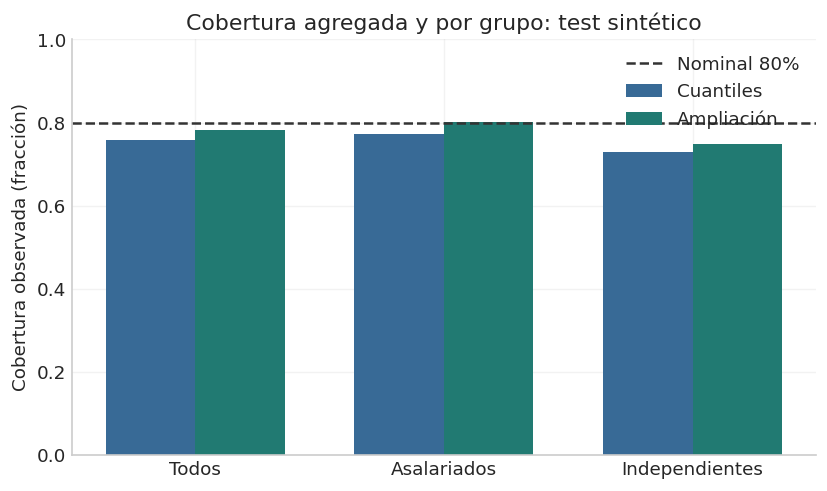

In [3]:
alpha=.2
scores=np.maximum.reduce([lo_cal-y[cal],y[cal]-hi_cal,np.zeros(len(cal))])
k=math.ceil((len(cal)+1)*(1-alpha))
assert k<=len(cal)
qhat=np.sort(scores)[k-1]
lo_c,hi_c=lo-qhat,hi+qhat
coverage_raw=((y[test]>=lo)&(y[test]<=hi))
coverage_c=((y[test]>=lo_c)&(y[test]<=hi_c))
coverage_table=[]
for label,mask in [('Todos',np.ones(len(test),bool)),('Asalariados',independent[test]==0),('Independientes',independent[test]==1)]:
    coverage_table.append({'población':label,'n':int(mask.sum()),'cobertura_original':coverage_raw[mask].mean(),'cobertura_ampliada':coverage_c[mask].mean(),'ancho_medio_COP':np.mean(np.exp(hi_c[mask])-np.exp(lo_c[mask]))})
coverage_table=pd.DataFrame(coverage_table);display(coverage_table)
fig,ax=plt.subplots();positions=np.arange(3)
ax.bar(positions-.18,coverage_table['cobertura_original'],width=.36,label='Cuantiles',color=BLUE)
ax.bar(positions+.18,coverage_table['cobertura_ampliada'],width=.36,label='Ampliación',color=TEAL)
ax.axhline(.8,linestyle='--',color='#333333',label='Nominal 80%');ax.set_xticks(positions,coverage_table['población'])
ax.set(ylim=(0,1),ylabel='Cobertura observada (fracción)',title='Cobertura agregada y por grupo: test sintético');ax.legend();plt.show()

La garantía marginal de la construcción requiere intercambiabilidad; no promete cobertura en cada segmento. La tabla muestra grupo, tamaño y ancho. Conservar grupos con peor cobertura aunque el agregado esté cerca de 80%.

## 3. Bandas en moneda y cambio de distribución


La exponencial es monótona: la banda de log ingreso puede transformarse a COP. Después se desplaza solo el ingreso de prueba en 0,4 log puntos, manteniendo la banda congelada: se viola el mecanismo estacionario de calibración.

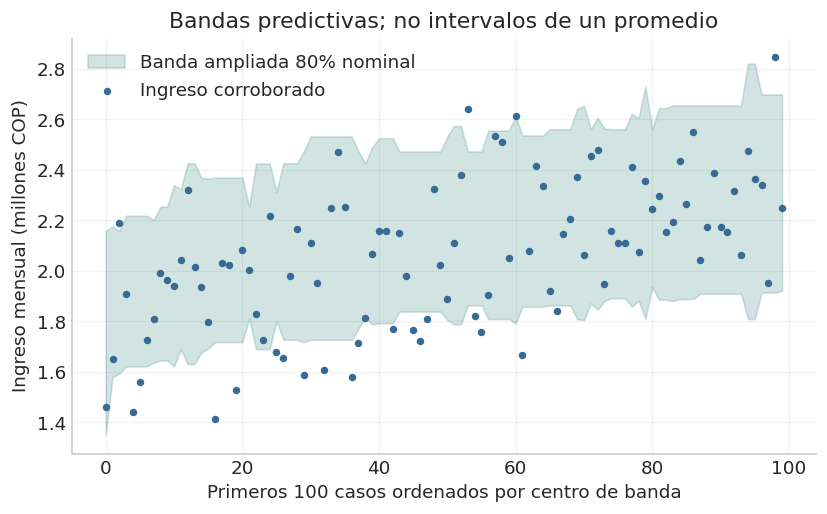

,escenario,cobertura
0,Estacionario,0.7829
1,"Desplazamiento +0,4 log",0.2057


In [4]:
order=np.argsort((lo_c+hi_c)/2)[:100]
fig,ax=plt.subplots();axis=np.arange(len(order))
ax.fill_between(axis,np.exp(lo_c[order])/1e6,np.exp(hi_c[order])/1e6,color=TEAL,alpha=.2,label='Banda ampliada 80% nominal')
ax.scatter(axis,np.exp(y[test][order])/1e6,s=12,color=BLUE,label='Ingreso corroborado')
ax.set(xlabel='Primeros 100 casos ordenados por centro de banda',ylabel='Ingreso mensual (millones COP)',title='Bandas predictivas; no intervalos de un promedio');ax.legend();plt.show()
shifted=y[test]+.4
shift_coverage=((shifted>=lo_c)&(shifted<=hi_c)).mean()
display(pd.DataFrame({'escenario':['Estacionario','Desplazamiento +0,4 log'],'cobertura':[coverage_c.mean(),shift_coverage]}))

La banda describe un ingreso corroborado hipotético, no la honestidad de una declaración. Una declaración fuera de banda puede motivar aclaración; no confirma fraude. La sensibilidad bajo cambio de distribución conserva un fallo potencial de cobertura.

## Desarrollo ampliado: modelo, estimación y uso


**Uso:** estimar un rango de ingreso corroborado y decidir cuándo pedir aclaraciones. **Entrada:** actividad, estacionalidad, cobertura de evidencia y tipo de ingreso; **salida:** distribución o banda monetaria, no probabilidad de fraude. El target debe ser ingreso verificado en la misma base temporal y monetaria que la declaración.

Los cuantiles describen dispersión individual, no incertidumbre de una media. La calibración conformal requiere condiciones de intercambio; una evaluación temporal debe investigar dependencia y cambio de régimen. Se amplía el desarrollo con pérdida pinball, un modelo de dos partes, validación por grupo y severidad de discrepancia.

In [5]:
advanced_metrics = {}
advanced_rng = np.random.default_rng(9221)

### 4. Por qué la pérdida pinball estima un cuantil


Para una predicción constante a, $E[\rho_\tau(Y-a)]$ tiene derivada $F_Y(a)-\tau$ donde existe. El mínimo satisface $F_Y(a)=\tau$. Por eso variar tau cambia el punto de la distribución que se estima.

$$\rho_\tau(u)=\begin{cases}\tau u,&u\ge0,\\(\tau-1)u,&u<0.\end{cases}$$

El error cuadrático estima una media y no sustituye a esta pérdida. El siguiente contraste verifica numéricamente la posición del mínimo en una población asimétrica.

In [6]:
pinball_sample=advanced_rng.lognormal(0,.7,1500)
constant_grid=np.linspace(.1,4,500)
pinball_records=[]
for tau in [.1,.5,.9]:
    u=pinball_sample[:,None]-constant_grid[None,:]
    losses=np.mean(np.maximum(tau*u,(tau-1)*u),axis=0)
    minimizer=constant_grid[np.argmin(losses)]
    empirical=float(np.quantile(pinball_sample,tau))
    pinball_records.append({'tau':tau,'minimo_grilla':minimizer,'cuantil_empirico':empirical,'error':abs(minimizer-empirical)})
display(pd.DataFrame(pinball_records))
assert max(z['error'] for z in pinball_records)<.03

,tau,minimo_grilla,cuantil_empirico,error
0,0.1000,0.4204,0.4216,0.0012
1,0.5000,1.0691,1.0704,0.0013
2,0.9000,2.5385,2.5392,0.0007


**Interpretación y uso.** El mínimo se aproxima con una grilla; el error permitido refleja su resolución. En un modelo condicional, la misma lógica se aplica para cada X bajo capacidad de estimación suficiente y no demuestra calibración por grupo.

### 5. Ingresos cero: probabilidad y monto positivo


Con $\pi_0(X)=P(I=0\mid X)$ y $F_+(u\mid X)$ para I positivo:
$$F_I(u\mid X)=\pi_0(X)+(1-\pi_0(X))F_+(u\mid X),\quad u>0.$$

Para obtener el cuantil tau: es cero si $\tau\le\pi_0$; si no, se busca el cuantil positivo $(\tau-\pi_0)/(1-\pi_0)$. Un cero observado y ausencia de evidencia son estados distintos.

In [7]:
from sklearn.linear_model import LogisticRegression,LinearRegression
from scipy.stats import norm
hurdle_n=2500
hurdle_x=advanced_rng.uniform(0,1,(hurdle_n,2))
true_zero_p=1/(1+np.exp(-(-2+2*hurdle_x[:,1])))
hurdle_zero=advanced_rng.binomial(1,true_zero_p)
positive_log=np.log(2_000_000)+.5*hurdle_x[:,0]+advanced_rng.normal(0,.25,hurdle_n)
hurdle_income=np.where(hurdle_zero==1,0,np.exp(positive_log))
hurdle_train=np.arange(1500);hurdle_test=np.arange(1500,2500)
zero_model=LogisticRegression(C=10,max_iter=500).fit(hurdle_x[hurdle_train],hurdle_zero[hurdle_train])
positive_train=hurdle_train[hurdle_zero[hurdle_train]==0]
amount_model=LinearRegression().fit(hurdle_x[positive_train],positive_log[positive_train])
residual_sigma=float(np.std(positive_log[positive_train]-amount_model.predict(hurdle_x[positive_train]),ddof=3))
p0=zero_model.predict_proba(hurdle_x[hurdle_test])[:,1]
mu=amount_model.predict(hurdle_x[hurdle_test])
def hurdle_quantile(tau):
    adjusted=np.clip((tau-p0)/(1-p0),1e-9,1-1e-9)
    return np.where(tau<=p0,0,np.exp(mu+residual_sigma*norm.ppf(adjusted)))
hurdle_lower,hurdle_upper=hurdle_quantile(.1),hurdle_quantile(.9)
hurdle_coverage=np.mean((hurdle_income[hurdle_test]>=hurdle_lower)&(hurdle_income[hurdle_test]<=hurdle_upper))
display(pd.DataFrame({'metrica':['Brier de ingreso cero','Cobertura banda 0,1–0,9','Fracción cero real test'],'valor':[brier_score_loss(hurdle_zero[hurdle_test],p0),hurdle_coverage,hurdle_zero[hurdle_test].mean()]}))
assert (hurdle_lower<=hurdle_upper).all()

,metrica,valor
0,Brier de ingreso cero,0.1888
1,"Cobertura banda 0,1–0,9",0.8960
2,Fracción cero real test,0.2750


**Interpretación y uso.** El monto positivo se supone lognormal y homocedástico en este nuevo generador; es un modelo distinto del boosting anterior. La masa puntual en cero puede hacer conservadora una banda nominal. No se fija un cero porque no llegó el extracto.

### 6. Cobertura por grupo con incertidumbre binomial


Para una cobertura observada $\hat c=k/n$, el intervalo Wilson evita el intervalo normal simétrico que puede salir de [0,1]. Su forma usa
$$\frac{\hat c+z^2/(2n)\ \pm\ z\sqrt{\hat c(1-\hat c)/n+z^2/(4n^2)}}{1+z^2/n}.$$

Es incertidumbre de proporción bajo observaciones independientes, no garantía bajo dependencia temporal ni corrección por seleccionar muchos grupos.

,grupo,n,cobertura,low,high
0,Asalariados,449,0.8018,0.7624,0.8360
1,Independientes,251,0.7490,0.6919,0.7986


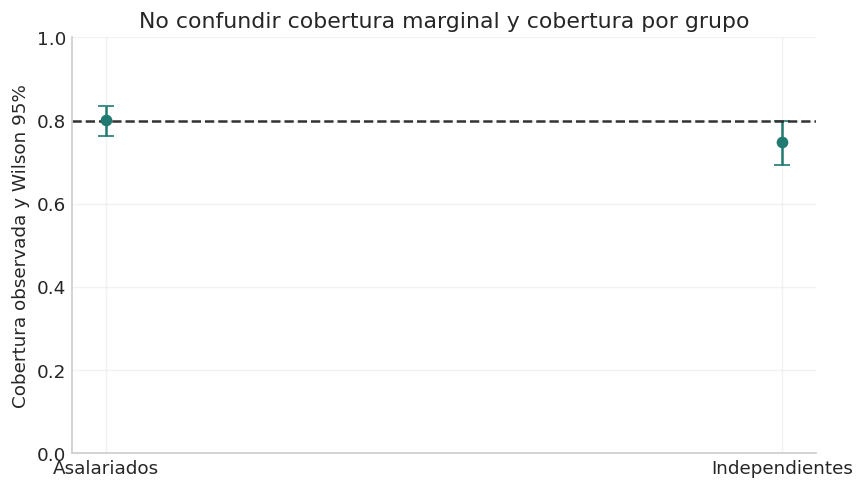

In [8]:
def coverage_wilson(k,n,z=1.96):
    proportion=k/n;denominator=1+z*z/n
    center=(proportion+z*z/(2*n))/denominator
    radius=z*np.sqrt(proportion*(1-proportion)/n+z*z/(4*n*n))/denominator
    return center-radius,center+radius
coverage_intervals=[]
for group in [0,1]:
    mask=independent[test]==group
    successes=int(coverage_c[mask].sum());size=int(mask.sum())
    low,high=coverage_wilson(successes,size)
    coverage_intervals.append({'grupo':['Asalariados','Independientes'][group],'n':size,'cobertura':successes/size,'low':low,'high':high})
coverage_intervals=pd.DataFrame(coverage_intervals);display(coverage_intervals)
fig,ax=plt.subplots();positions=np.arange(2)
ax.errorbar(positions,coverage_intervals['cobertura'],yerr=[coverage_intervals['cobertura']-coverage_intervals['low'],coverage_intervals['high']-coverage_intervals['cobertura']],fmt='o',color=TEAL,capsize=5)
ax.axhline(.8,color='#333333',linestyle='--');ax.set_xticks(positions,coverage_intervals['grupo'])
ax.set(ylim=(0,1),ylabel='Cobertura observada y Wilson 95%',title='No confundir cobertura marginal y cobertura por grupo');plt.show()

**Interpretación y uso.** Una diferencia entre grupos necesita una comparación específica; no se declara significancia por mirar dos barras de error. El intervalo cuantifica muestreo en este generador, no corrige cambio de distribución.

### 7. De una banda a una discrepancia investigable


Una señal propuesta, no una probabilidad de fraude, es
$$d_i=\max\left(0,\frac{\log D_i-\hat q_u(X_i)}{\hat q_u(X_i)-\hat q_l(X_i)+\varepsilon}\right).$$

D es ingreso declarado en la misma base. Al usar el ancho, una discrepancia en un grupo incierto tiene otra interpretación. Se requiere evidencia independiente para una etiqueta de tergiversación.

Casos fuera del rango gráfico: 0


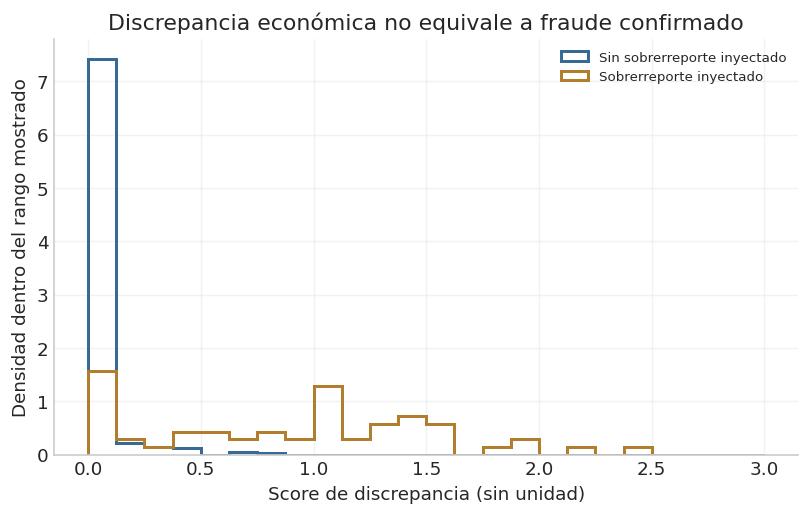

In [9]:
declaration=np.exp(y[test])
synthetic_overstatement=advanced_rng.binomial(1,.07,len(test)).astype(bool)
declaration[synthetic_overstatement]*=1.8
width=hi_c-lo_c
income_discrepancy=np.maximum(0,(np.log(declaration)-hi_c)/(width+1e-8))
fig,ax=plt.subplots()
for flag,label,color in [(False,'Sin sobrerreporte inyectado',BLUE),(True,'Sobrerreporte inyectado',GOLD)]:
    values=income_discrepancy[synthetic_overstatement==flag]
    ax.hist(values,bins=np.linspace(0,3,25),density=True,histtype='step',linewidth=1.8,color=color,label=label)
ax.set(xlabel='Score de discrepancia (sin unidad)',ylabel='Densidad dentro del rango mostrado',title='Discrepancia económica no equivale a fraude confirmado');ax.legend(fontsize=8);plt.show()
print('Casos fuera del rango gráfico:',int((income_discrepancy>3).sum()))
advanced_metrics.update({'Cobertura modelo de dos partes':round(float(hurdle_coverage),4),'AP de sobrerreporte sintético':round(float(average_precision_score(synthetic_overstatement,income_discrepancy)),4),'Error máximo de pinball en grilla':round(max(z['error'] for z in pinball_records),4)})

**Interpretación y uso.** El target inyectado sirve para explorar sensibilidad, no para declarar desempeño de detección documental. El histograma acota su rango y se publica el número de casos omitidos; los faltantes requieren ruta de evidencia y no score artificialmente bajo.

## Comprobaciones y límites

Las identidades y contraejemplos siguientes son parte del experimento; no verifican desempeño productivo.

In [10]:
assert qhat>=0
assert np.all(lo_c<=hi_c)
assert coverage_c.mean()>=coverage_raw.mean()
assert shift_coverage<coverage_c.mean()

## Resultados computados

In [11]:
metrics = {'Cobertura nominal': .8, 'Cobertura test ampliada': round(float(coverage_c.mean()),4), 'Cobertura con cambio de ingreso': round(float(shift_coverage),4), 'Ampliación en log puntos': round(float(qhat),4)}
metrics.update(advanced_metrics)
print("LAB_METRICS:" + json.dumps(metrics, ensure_ascii=False))

LAB_METRICS:{"Cobertura nominal": 0.8, "Cobertura test ampliada": 0.7829, "Cobertura con cambio de ingreso": 0.2057, "Ampliación en log puntos": 0.0097, "Cobertura modelo de dos partes": 0.896, "AP de sobrerreporte sintético": 0.7895, "Error máximo de pinball en grilla": 0.0013}


## Ideas y preguntas para continuar

1. Comparar calibración marginal y por segmento, con tamaños mínimos.
2. Incorporar ingresos cero mediante un modelo en dos partes.
3. Tratar períodos faltantes como cobertura de evidencia y no ingreso cero.
4. Diseñar indicadores de cambio de régimen antes de recalibrar.
5. Separar discrepancia de ingreso de tergiversación adjudicada.

## Fuentes y relación con el proyecto

- [Romano, Patterson y Candès: Conformalized Quantile Regression](https://arxiv.org/abs/1905.03222).
- [scikit-learn: regresión cuantílica con boosting](https://scikit-learn.org/stable/auto_examples/ensemble/plot_gradient_boosting_quantile.html).

Consultar también `../README.md` y `../../MODEL_AND_LOSS_METHODS.md`.

## Uso responsable y ficha mínima de salida

Antes de una aplicación institucional, registrar población, corte de información, versión del modelo, horizonte, unidades y cobertura de fuentes. Separar score de anomalía, probabilidad estimada y costo por acción. Una discrepancia o un desvío requiere evidencia independiente antes de llamarlo fraude. El experimento está completo en su alcance sintético; no sustituye calibración externa, integración de datos o validación independiente.

## Preguntas para refutar el desarrollo

1. ¿La mejora persiste al cambiar el mecanismo generador y la cohorte?
2. ¿Qué variable solo estaría disponible después de decidir?
3. ¿Cuánto del beneficio depende de una eficacia o cobertura supuesta?
4. ¿Qué caso legítimo produce la misma señal?
5. ¿Puede otra persona reconstruir el resultado desde las celdas y los parámetros?

## Diccionario de símbolos y unidades

| Símbolo | Significado en este notebook | Unidad o restricción |
|---|---|---|
| I, D | Ingreso corroborado y declarado | COP mensuales, misma base |
| y | Logaritmo del ingreso positivo | No aplicarlo a cero sin otro modelo |
| τ, α | Cuantil y error nominal de cobertura | Fracciones, propósitos distintos |
| s, ŝ | No conformidad y ampliación calibrada | Log puntos en el experimento |
| π₀ | Probabilidad de ingreso cero | No es falta de evidencia |
| σ | Desviación del monto log positivo | Supuesto normal homocedástico del modelo de dos partes |

## Modelos y casos de uso

| Modelo o técnica | Para qué usarlo | Condición para interpretar su salida |
|---|---|---|
| Boosting cuantílico | Estimar rangos de ingreso verificado | Reportar ancho y cobertura por segmento |
| Ampliación conformal | Ajustar cobertura marginal | No garantiza cobertura bajo drift |
| Modelo de dos partes | Tratar masa cero y montos positivos | Separar no observado de ingreso cero |
| Score de discrepancia | Priorizar aclaración documental | No es probabilidad de fraude ni prueba forense |

Referencias técnicas adicionales: [logit](https://scikit-learn.org/stable/modules/linear_model.html), [beta-binomial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.betabinom.html), [MILP](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html). Las distribuciones, datos y resultados de este notebook son sintéticos y se generan en las celdas.